In [1]:
# Parameters
name      = ""
fits_path = ""

In [2]:
# Parameters
name = "FLAMES-30Dor-6563"
fits_path = "fits_ready/FLAMES-30Dor-6563.fits"


In [3]:
import time
start_time=time.time()

In [4]:
import numpy as np
import seaborn as sns
import pandas as pd
import sys
from pathlib import Path
import astropy.units as u
from matplotlib import pyplot as plt
import corner
import json
from astropy.io import fits
from lmfit.model import save_modelresult


# Add path to py_modules 
sys.path.append(str(Path().resolve() / 'py_modules')) # 1 level up = project root

#import strucfunc                   
from strucfunc import sosflog
import fit_structure_function
import ci_results_compiler
import bfunc
import bplot
import list_maps_plots

# Velocity Field

In [5]:
from astropy.table import Table

data_in = Table.read("fits_ready/" + name + ".fits", hdu=name)
data_frame = data_in.to_pandas()

In [6]:
with fits.open("fits_ready/" + name + ".fits") as hdul:
    hdr = hdul[0].header

hdr

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                    8 / array data type                                
NAXIS   =                    0 / number of array dimensions                     
EXTEND  =                    T                                                  
FILE    = 'FLAMES-30Dor-6563'  / Fits file name                                 
NAME_ID = 'FLAMES-30Dor-H-X'   / pipeline identifier                            
REG     = 'NGC 2070'           / Region catalog name                            
NAME_REG= '30 Doradus'         / Region name                                    
REG_ID  = '30Dor   '           / Region identifier                              
TYPE_OBJ= 'H II region'        / Type object                                    
DIST    =                50000 / Distance in parsecs                            
INSTR   = 'FLAMES  '           / Instrument                                     
LINE    = 'H$\alpha$'       

In [7]:
#m3D      = hdul[0].header['M3D']
#ra       = hdul[0].header['RA']
sig      = hdul[0].header['SIG']
sig2     = hdul[0].header['SIG2']
s0       = hdul[0].header['S0']
#noise    = hdul[0].header['NOISE']
box_size = hdul[0].header['BOX_SIZE']
pc       = hdul[0].header['PC']
pix      = hdul[0].header['PIX']
line     = hdul[0].header['LINE']
binsize  = hdul[0].header['BINSIZE']

In [8]:
hdul.info()

Filename: fits_ready/FLAMES-30Dor-6563.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      22   ()      


C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\FLAMES_30dor\structure_function\one_component_Lfracc\py_modules\list_maps_plots.py:766: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 1, 0.96])


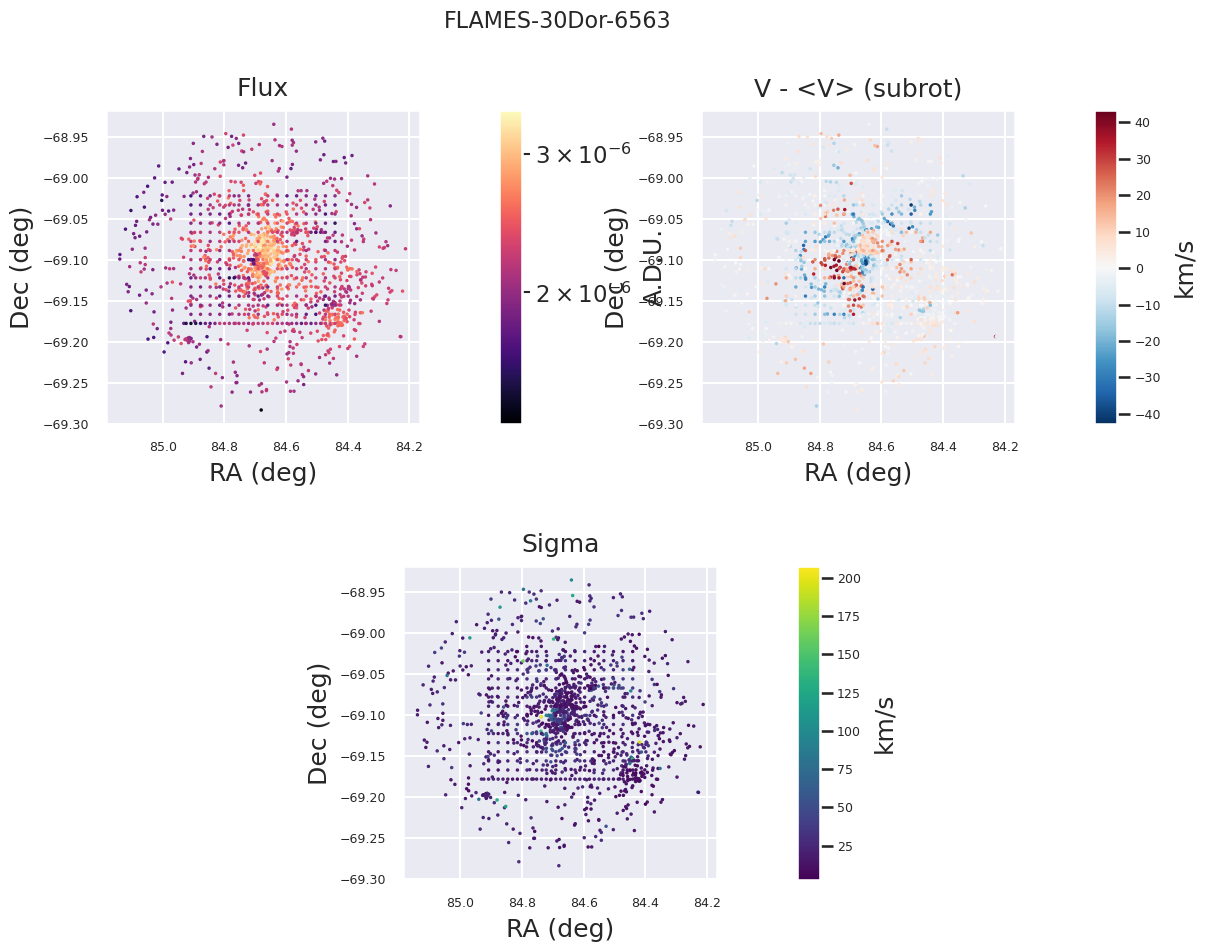

<Figure size 640x480 with 0 Axes>

In [9]:
fig, ax = list_maps_plots.plot_panels_norm(data_frame,
                                                s = 1.0,
                                                invert_ra=True,
                                                figsize=(14, 10),
                                                box_aspect=1.0,
                                                flux_normalization_value=1.710726e+06,
                                                figure_title = name)
plt.show()
plt.savefig('Imgs/' + name + '.jpg', bbox_inches='tight')

In [10]:
data_frame

,RAdeg,DEdeg,V_mean,log_F,sigma
0,84.550875,-69.148917,-2.775576,3.980130,10.705632
1,84.634750,-69.088028,4.344645,5.050337,11.376043
2,84.852375,-69.082583,-33.764827,4.063845,10.314624
3,84.610125,-69.163389,-0.596002,3.892574,15.575936
4,84.460167,-69.170167,1.242338,4.282470,5.439301
...,...,...,...,...,...
1352,84.721708,-69.122194,-32.478608,3.087947,81.761108
1353,84.768417,-69.177750,-6.360495,3.592798,15.923745
1354,84.768417,-69.033306,5.505637,3.668402,24.747502
1355,84.768417,-69.066639,-13.473946,4.106189,16.710389


# Structure function

In [11]:
#data_frame.columns=['X','Y','RV','I','Sig']
base_names = ['X', 'Y', 'RV', 'I', 'Sig']
data_frame.columns = base_names + list(data_frame.columns[5:])

In [12]:
table = sosflog(data_frame, 0.05, 3600)

C:\Users\javas\anaconda3\envs\viento\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\javas\anaconda3\envs\viento\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\FLAMES_30dor\structure_function\one_component_Lfracc\py_modules\strucfunc.py:284: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  pairs.s_class[pairs.s_class == 0] = 1


In [13]:
s = 0.5 * (table[('s', 'min')] + table[('s', 'max')])*pc
e_s = 0.5 * (table[('s', 'max')] - table[('s', 'min')])*pc
b2 = table[('dV2', 'mean')]
ng = table[('dV2', 'count')]
e_b2 = table[('dV2', 'std')] / np.sqrt(ng)

In [14]:
#"Sum dv^2":
#"Sum weights":
#"Sum w * dv^2"
#"N pairs":
#"Weighted B(r)"

Br_results = {
    'log10 r'        : np.log10(s),
    'r'              : s,
    'r_err'          : e_s,
    "Unweighted B(r)": b2,
    'Unweighted B(r)_err' : e_b2
}

Br_results_ = pd.DataFrame(Br_results)
Br = Br_results_ 

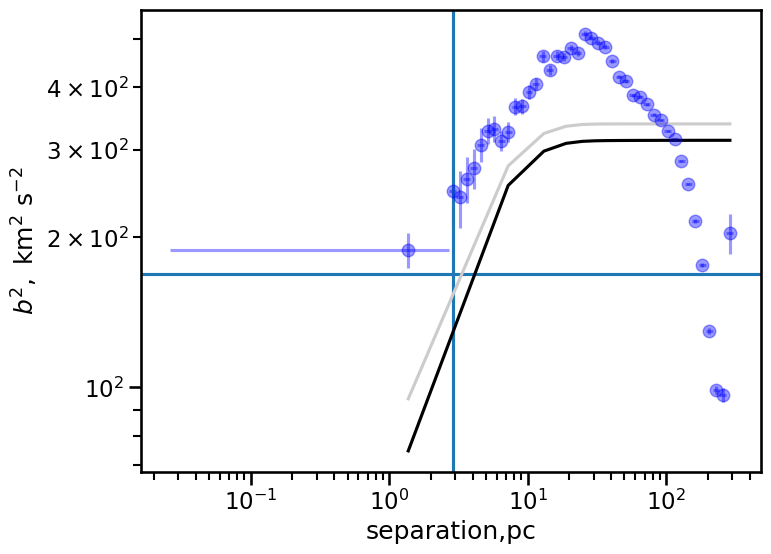

In [15]:
r0    = np.interp(sig2, b2[1:35], s[1:35])
ra = r0
m     = 1
noise = 0

rgrid = np.linspace(s.min(), s.max())

fig, ax = plt.subplots(figsize=(8, 6))

ax.errorbar(s, b2, yerr=e_b2, xerr=e_s, fmt='o', alpha=0.4,color="blue")

ax.axhline(sig2, ls='-')
ax.axvline(r0, ls='-')

ax.plot(rgrid, bfunc.bfunc00s(rgrid, r0, sig2, m), color="0.8")
ax.plot(rgrid, bfunc.bfunc03s(rgrid, r0, sig2, m, s0, noise), color="black")
#ax.plot(rgrid, bfunc.bfunc04s(rgrid, r0, sig2, m, s0, noise, box_size), color="black")


ax.set(xscale='log', yscale='log', 
       xlabel='separation,pc',
       ylabel=r'$b^2,\ \mathrm{km^2\ s^{-2}}$'
      )
None

plt.show()



# Export

In [16]:
df =  Br_results_.copy()

# Flatten MultiIndex columns like ('s','count') -> "s_count"
if isinstance(df.columns, pd.MultiIndex):
    df.columns = ["_".join(map(str, col)).strip() for col in df.columns.to_flat_index()]
else:
    df.columns = [str(c) for c in df.columns]

# (Optional) drop index to avoid it becoming an extra column
df = df.reset_index(drop=True)

t = Table.from_pandas(df)
new_hdu = fits.BinTableHDU(t, name="TABLE")

In [17]:
#with fits.open(fits_path, mode="readonly") as hdul:
#    hdus = [h.copy() for h in hdul]   # copy existing HDUs

#hdus.append(new_hdu)
#fits.HDUList(hdus).writeto(fits_path, overwrite=True)

In [18]:
with fits.open(fits_path, memmap=False) as hdul:
    hdus = [h.copy() for h in hdul]

# FITS EXTNAMEs are effectively case-insensitive; astropy reports them uppercase.
target = "TABLE"
idxs = [i for i, h in enumerate(hdus) if h.name.upper() == target]

if idxs:
    i0 = idxs[0]
    # Optional: preserve existing header cards (metadata) from old PARAMETERS
    old_hdr = hdus[i0].header.copy()
    hdus[i0] = new_hdu
    # Keep old metadata, then ensure EXTNAME stays correct
    hdus[i0].header.update(old_hdr)
    hdus[i0].name = target
    # Remove any additional duplicates if they exist
    for j in reversed(idxs[1:]):
        del hdus[j]
else:
    # If it doesn't exist, add it
    hdus.append(new_hdu)

fits.HDUList(hdus).writeto(fits_path, overwrite=True)

In [19]:
with fits.open(fits_path) as hdul:
    hdul.info()

Filename: fits_ready/FLAMES-30Dor-6563.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      22   ()      
  1  FLAMES-30DOR-6563    1 BinTableHDU     19   1357R x 5C   [D, D, D, D, D]   
  2  TABLE         1 BinTableHDU     19   42R x 5C   [D, D, D, D, D]   


In [20]:
# Test import

from astropy.table import Table
t = Table.read(fits_path, hdu="TABLE")
df_loaded = t.to_pandas()


In [21]:
print("--- %s seconds ---" % (time.time()-start_time))

--- 12.33842396736145 seconds ---
